# Question 5: Student Academic Success

In [94]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, roc_auc_score)
from sklearn.preprocessing import StandardScaler


# Load the file
df = pd.read_csv("student_academic_success.csv", sep=";")

print("Dataset shape:", df.shape)
print("Missing values:",df.isna().sum().sum())
pd.set_option("display.max_columns", None)
df.head()

Dataset shape: (4424, 37)
Missing values: 0


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [97]:
#Create one stratified split of the row indices
train_idx, test_idx = train_test_split(
df.index,
test_size=0.25,
random_state=5805,
stratify=df["Target"],
)

#The enrollment-time feature set
entry_features = [
"Admission grade",
"Age at enrollment",
"Displaced",
"Educational special needs",
"Debtor",
"Tuition fees up to date",
"Gender",
"Scholarship holder",
"International",
]

#The academic-progress feature

progress_features = [
"Curricular units 1st sem (enrolled)",
"Curricular units 1st sem (evaluations)",
"Curricular units 1st sem (approved)",
"Curricular units 1st sem (grade)",
"Curricular units 1st sem (without evaluations)",
"Curricular units 2nd sem (enrolled)",
"Curricular units 2nd sem (evaluations)",
"Curricular units 2nd sem (approved)",
"Curricular units 2nd sem (grade)",
"Curricular units 2nd sem (without evaluations)",
]

In [98]:
print("Full data")
full_counts = df["Target"].value_counts().sort_index()
print(full_counts)
print("Total:", full_counts.sum())

print("Training set")
train_counts = df.loc[train_idx, "Target"].value_counts().sort_index()
print(train_counts)
print("Total:", train_counts.sum())

print("Test set")
test_counts = df.loc[test_idx, "Target"].value_counts().sort_index()
print(test_counts)
print("Total:", test_counts.sum())

Full data
Target
Dropout     1421
Enrolled     794
Graduate    2209
Name: count, dtype: int64
Total: 4424
Training set
Target
Dropout     1066
Enrolled     595
Graduate    1657
Name: count, dtype: int64
Total: 3318
Test set
Target
Dropout     355
Enrolled    199
Graduate    552
Name: count, dtype: int64
Total: 1106


## 5a. Audit and split

- **Dataset shape:** 4,424 rows × 37 columns
- **Missing values:** 0

| Target | Full data | Training set | Test set |
| --- | ---: | ---: | ---: |
| Dropout | 1,421 | 1,066 | 355 |
| Enrolled | 794 | 595 | 199 |
| Graduate | 2,209 | 1,657 | 552 |
| **Total** | **4,424** | **3,318** | **1,106** |

As we see the number, it's easy to tell that the stratification guarantees that both test set, training set will contains all 3 target class. But stratification does not guarantee that all 3 class size will be equally distributed.

In [ ]:
###Start of code for 5b
X_train = df.loc[train_idx, entry_features]
y_train = df.loc[train_idx, "Target"]

X_test = df.loc[test_idx, entry_features]
y_test = df.loc[test_idx, "Target"]

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(3318, 9) (1106, 9)
(3318,) (1106,)


In [101]:
def report_test_metrics(y_true, y_pred, title="Confusion matrix"):
    labels = ["Dropout", "Enrolled", "Graduate"]

    report = classification_report(y_true, y_pred, labels=labels, output_dict=True)
    score_rows = labels + ["macro avg", "weighted avg"]
    scores = pd.DataFrame({label: report[label] for label in score_rows}).T
    scores = scores[["precision", "recall", "f1-score", "support"]]
    scores = scores.round(3)
    scores["support"] = scores["support"].astype(int)

    accuracy = pd.DataFrame(
        {"accuracy": [round(accuracy_score(y_true, y_pred), 3)]}
    )

    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(
        confusion_matrix(y_true, y_pred, labels=labels), display_labels=labels
    ).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)

    cm = pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=labels),
        index=pd.Index(labels, name="True"),
        columns=pd.Index(labels, name="Predicted"),
    )

    display(accuracy)
    display(scores)
    display(cm)
    return accuracy, scores, cm


,accuracy
0,0.617


,precision,recall,f1-score,support
Dropout,0.613,0.572,0.592,355
Enrolled,0.333,0.005,0.010,199
Graduate,0.619,0.866,0.722,552
macro avg,0.522,0.481,0.441,1106
weighted avg,0.566,0.617,0.552,1106


Predicted,Dropout,Enrolled,Graduate
True,,,
Dropout,203,1,151
Enrolled,55,1,143
Graduate,73,1,478


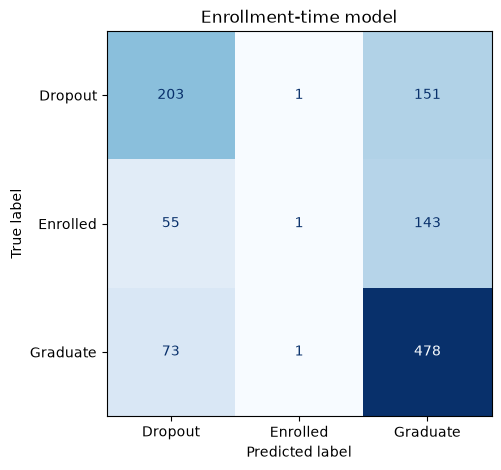

In [102]:
model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, solver="lbfgs")
    )
#Fit the entire pipeline only on the training rows
model.fit(X_train, y_train)

#Predict the test rows
y_pred = model.predict(X_test)
accuracy_b, scores_b, cm_b = report_test_metrics(
    y_test, y_pred, title="Enrollment-time model"
)


# 5b. An Enrollment-time softmax model
The accuracy, macroF1, and weightedF1 differ because the Accuracy weighs equal per sample where every class matters equally. Macro F1 gives each class one vote. It is the ordinary average of the three F1 scores. Meanwhile, Weighted F1 gives each class a vote proportional to its support. Therefore, those 3 differs fromeach other


By looking at the confusion matrix above:

First, let's consider Dropout class. There are total 355 students in test set for Dropout class, and the model predict 203 students correctly, 152 students were predicted wrong. Turns out 43% of the data were predicted right.

Second, let's consider Enrolled class. There are total 199 students in test set for Enrolled class, and the model predict 1 students correctly, 198 students were predicted wrong. Turns out only 0.5% of the data were predicted right.

Lastly, let's consider Graduate class. There are total 552 students in test set for Graduate class, and the model predict 478 students correctly, 73 students were predicted wrong. Turns out 86% of the data were predicted right.

Therefore, The model perform worst for "Enrolled Class"

(3318, 19) (1106, 19)
19


,accuracy
0,0.78


,precision,recall,f1-score,support
Dropout,0.821,0.775,0.797,355
Enrolled,0.542,0.387,0.452,199
Graduate,0.812,0.926,0.865,552
macro avg,0.725,0.696,0.705,1106
weighted avg,0.767,0.780,0.769,1106


Predicted,Dropout,Enrolled,Graduate
True,,,
Dropout,275,40,40
Enrolled,44,77,78
Graduate,16,25,511


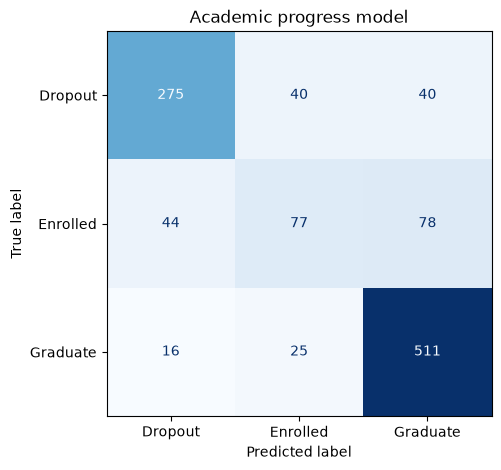

In [108]:
#5.c code
#Combining the 2 features list

combined_features = entry_features + progress_features

#Splitting the data into training and test set
X_train_combined = df.loc[train_idx, combined_features]
X_test_combined  = df.loc[test_idx, combined_features]

print(X_train_combined.shape, X_test_combined.shape)
print(len(combined_features))

progress_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver="lbfgs", max_iter=2000),
)
progress_model.fit(X_train_combined, y_train)

y_pred_combined = progress_model.predict(X_test_combined)

accuracy_c, scores_c, cm_c = report_test_metrics(
    y_test, y_pred_combined, title="Academic progress model"
)




# 5c Adding academic progress

Quantify the changes in accuracy and macro F1: as we can see obviously, the accuracy increase from 0.617 to 0.78 by 0.163 and macro F1 increase from 0.441 to 0.705 by 0.264 after combining the 2 feature lists.

Suppose the stated deployment goal is to identify students who may need support on the day they first enroll. Using using the second-semester features would not be a valid improvement for that goal because Courses enrolled, exams taken, courses passed, and grades for the second semester do not exist yet, so a support decision that day cannot use them.

If the goal were instead to make predictions after the second semester had ended then those same features would be valid. Because The second-semester numbers should be klnown by the the time the second semester end.


,accuracy
0,0.777


,precision,recall,f1-score,support
Dropout,0.799,0.786,0.793,355
Enrolled,0.584,0.296,0.393,199
Graduate,0.794,0.944,0.863,552
macro avg,0.726,0.675,0.683,1106
weighted avg,0.758,0.777,0.756,1106


Predicted,Dropout,Enrolled,Graduate
True,,,
Dropout,279,28,48
Enrolled,53,59,87
Graduate,17,14,521


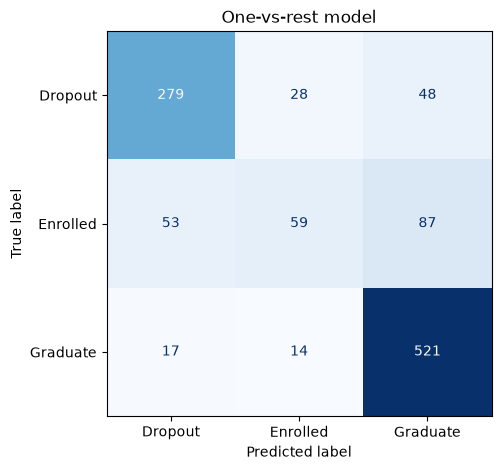

In [ ]:
#5d code
from sklearn.multiclass import OneVsRestClassifier
onevsrest_model = make_pipeline( 
                    StandardScaler(), 
                    OneVsRestClassifier( 
                      LogisticRegression(solver="lbfgs", max_iter=2000) 
                    ),
                 )
onevsrest_model.fit(X_train_combined, y_train)

y_pred_combined = onevsrest_model.predict(X_test_combined)

accuracy_c, scores_c, cm_c = report_test_metrics(
    y_test, y_pred_combined, title="One-vs-rest model"
)

# 5d Softmax versus one vs rest

Comparing those evaluation metrics, the progress-feature softmax is performing slightly better than the one vs rest. As accuracy is 0.77 vs 0.78, also macro f1 is 0.683 vs 0.704. Softmax trains one model for all three classes at once. Each student gets three scores, and those scores are turned into probabilities that add up to 1. Meanwhile, One-vs-rest trains three separate binary models. Each model learns on its own. At prediction time, the class whose model is most confident wins

In [112]:
#5e code
clf = progress_model.named_steps["logisticregression"]
class_index = {name: i for i, name in enumerate(clf.classes_)}

w_diff = clf.coef_[class_index["Dropout"]] - clf.coef_[class_index["Graduate"]]
b_diff = clf.intercept_[class_index["Dropout"]] - clf.intercept_[class_index["Graduate"]]

coef_diff = pd.Series(w_diff, index=combined_features)
coef_diff = coef_diff.reindex(coef_diff.abs().sort_values(ascending=False).index)

print("Intercept difference, bD - bG:", round(b_diff, 3))
print("The three largest: \n", coef_diff.round(3).head(3))


Intercept difference, bD - bG: 0.282
The three largest: 
 Curricular units 2nd sem (approved)   -3.163
Curricular units 2nd sem (enrolled)    1.984
Curricular units 1st sem (approved)   -1.690
dtype: float64


# 5e Pairwise coefficient interpretation
The magnitude of the largest coefficient is -3.163 which mean that a one-standard-deviation increase in courses approved lowers the log-odds of Dropout versus Graduate by 3.163. The sign is negative because the model learned that students who pass more second-semester courses are more often Graduate than Dropout
